# Étape 2 (axe 2D) : valider les données générées

Les données viennent de `landing/generate_data.m` : 500 vols de 20 s du drone `uav_plant.m` (le modèle des profs, 4 moteurs), récoltés en boucle fermée avec des consignes aléatoires en marches et du bruit de capteur (`g_noise = 0.1`).

Comme pour les CSV de l'axe vertical, on vérifie avant d'identifier un modèle :
1. formes, valeurs manquantes, expériences où le drone a perdu le contrôle ;
2. part des commandes saturées et des inclinaisons fortes ;
3. niveau du bruit ;
4. cohérence physique : un drone penché de $\theta$ accélère en $x$ de $g \tan\theta$ ;
5. découpage train / validation / test par expérience.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy.io import loadmat

D = loadmat("../data/raw/landing_data.mat")
U_common, U_diff = D["U_common"], D["U_diff"]           # (experiments, time steps)
Y = D["Y"]                                               # (experiments, time steps, 14)
names = [str(n[0]) for n in D["names_Y"][0]]
Ts = float(D["Ts"].squeeze())
lost = D["lost"].ravel().astype(bool)
iy = {n: i for i, n in enumerate(names)}                 # column index of each measurement
theta, ax, az = Y[:, :, iy["theta"]], Y[:, :, iy["ax"]], Y[:, :, iy["az"]]
t = np.arange(1, U_common.shape[1] + 1) * Ts

print("U_common", U_common.shape, " U_diff", U_diff.shape, " Y", Y.shape)
print("measurements:", names)
print("NaN:", np.isnan(Y).sum(), " lost experiments:", lost.sum())

U_common (500, 400)  U_diff (500, 400)  Y (500, 400, 14)
measurements: ['x', 'y', 'z', 'vx', 'vy', 'vz', 'phi', 'theta', 'psi', 'wx', 'wy', 'wz', 'ax', 'az']
NaN: 0  lost experiments: 0


## 1. Saturations et inclinaisons fortes

common thrust saturated (0 or 1): 1.6 % of the samples
front/rear difference saturated (+-0.1): 0.0 % of the samples
|theta| > 0.25 rad: 11.1 %,  > 0.5 rad: 0.57 %


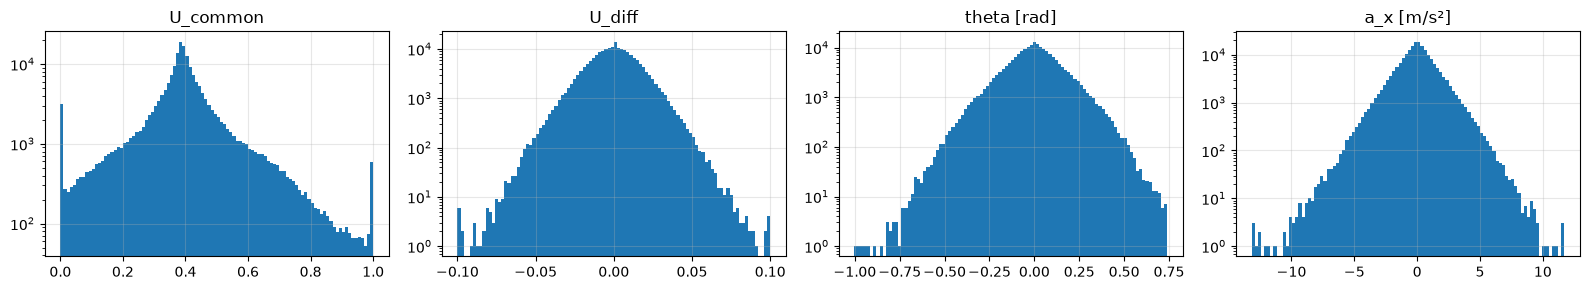

In [2]:
sat_common = np.mean((U_common <= 1e-4) | (U_common >= 1 - 1e-4))
sat_diff = np.mean(np.abs(U_diff) >= 0.0999)
print(f"common thrust saturated (0 or 1): {100 * sat_common:.1f} % of the samples")
print(f"front/rear difference saturated (+-0.1): {100 * sat_diff:.1f} % of the samples")
print(f"|theta| > 0.25 rad: {100 * np.mean(np.abs(theta) > 0.25):.1f} %,  > 0.5 rad: {100 * np.mean(np.abs(theta) > 0.5):.2f} %")

fig, axs = plt.subplots(1, 4, figsize=(16, 3))
for a, v, name in zip(axs, [U_common, U_diff, theta, ax], ["U_common", "U_diff", "theta [rad]", "a_x [m/s²]"]):
    a.hist(v.ravel(), bins=100, log=True); a.set_title(name); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Niveau du bruit
On retire la partie lente du signal (moyenne glissante sur 5 pas) : ce qui reste est essentiellement le bruit de capteur.

In [3]:
def noise_std(v, w=5):
    k = np.ones(w) / w
    smooth = np.array([np.convolve(r, k, mode="same") for r in v])
    return np.std((v - smooth)[:, w:-w])

for n in ["z", "theta", "ax", "az"]:
    print(f"{n:6s} noise std ≈ {noise_std(Y[:, :, iy[n]]):.4f}")

z      noise std ≈ 0.0064
theta  noise std ≈ 0.0060
ax     noise std ≈ 0.0600
az     noise std ≈ 0.2111


## 3. Cohérence physique : $a_x \approx g \tan\theta$
Si les données sont cohérentes, le nuage $a_x$ en fonction de $\tan\theta$ est une droite de pente $g = 9{,}81$.

fitted slope: a_x ≈ 9.818 * tan(theta)   (g = 9.81)


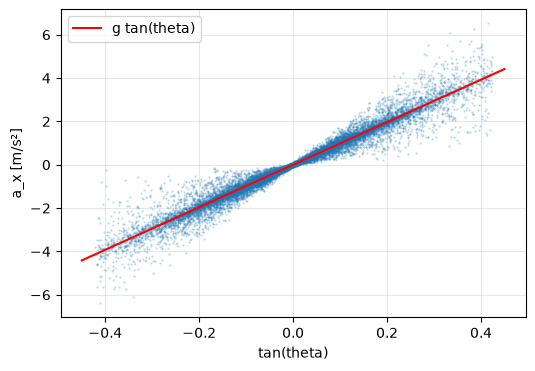

In [4]:
m = np.abs(theta) < 0.4
k = np.linalg.lstsq(np.tan(theta[m])[:, None], ax[m], rcond=None)[0][0]
print(f"fitted slope: a_x ≈ {k:.3f} * tan(theta)   (g = 9.81)")

idx = np.random.default_rng(0).choice(m.sum(), 20000, replace=False)
plt.figure(figsize=(6, 4))
plt.plot(np.tan(theta[m])[idx], ax[m][idx], ".", markersize=1, alpha=0.3)
x_line = np.linspace(-0.45, 0.45, 2); plt.plot(x_line, 9.81 * x_line, "r", label="g tan(theta)")
plt.xlabel("tan(theta)"); plt.ylabel("a_x [m/s²]"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Une expérience au hasard

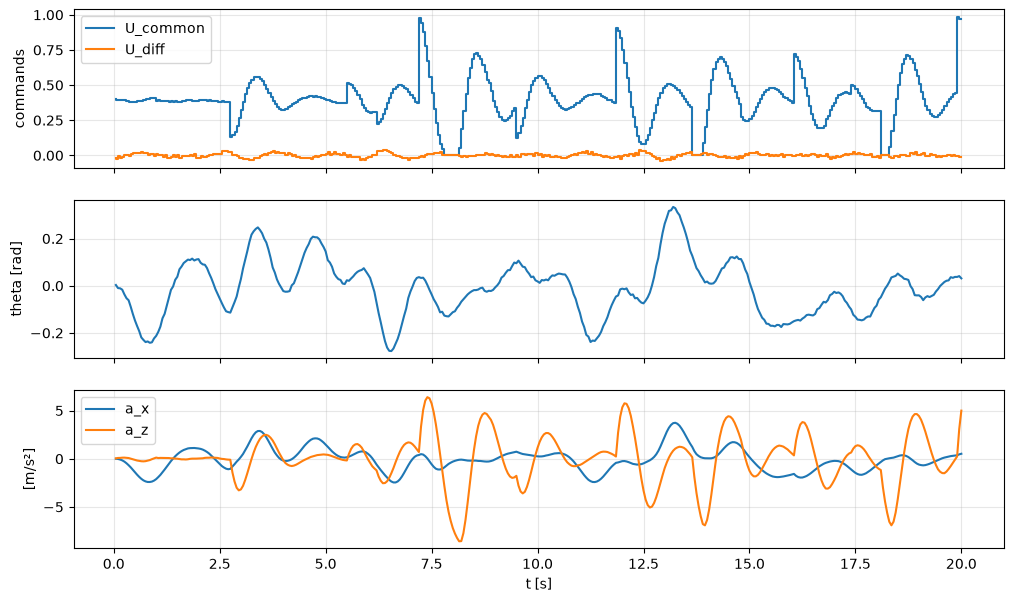

In [5]:
e = 7
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axs[0].step(t, U_common[e], label="U_common"); axs[0].step(t, U_diff[e], label="U_diff"); axs[0].legend(); axs[0].set_ylabel("commands")
axs[1].plot(t, theta[e]); axs[1].set_ylabel("theta [rad]")
axs[2].plot(t, ax[e], label="a_x"); axs[2].plot(t, az[e], label="a_z"); axs[2].legend(); axs[2].set_ylabel("[m/s²]"); axs[2].set_xlabel("t [s]")
for a in axs: a.grid(alpha=0.3)
plt.show()

## 5. Découpage train / validation / test (par expérience, 70 / 15 / 15)

In [6]:
keep = np.where(~lost)[0]                     # experiments kept
rng = np.random.default_rng(0)
perm = rng.permutation(keep)
n_tr, n_va = int(0.7 * len(perm)), int(0.15 * len(perm))
idx_train, idx_val, idx_test = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
print(len(idx_train), len(idx_val), len(idx_test))
np.savez("../data/raw/landing_split.npz", train=idx_train, val=idx_val, test=idx_test)

350 75 75
